# CareerPilot · One goal, two routes
**CA6123 · Member 1 · Orchestration walkthrough**

Use the same synthetic candidate in two sessions. First ask for a search. Then supply one job and prepare an application. Watch which calls run, which facts halt the workflow and which draft the candidate approves.

The specialist adapters replay local fixtures. Set `INTERACTIVE = True` to answer the two checkpoints yourself. The default run uses labelled fictional answers and consumes zero model calls.

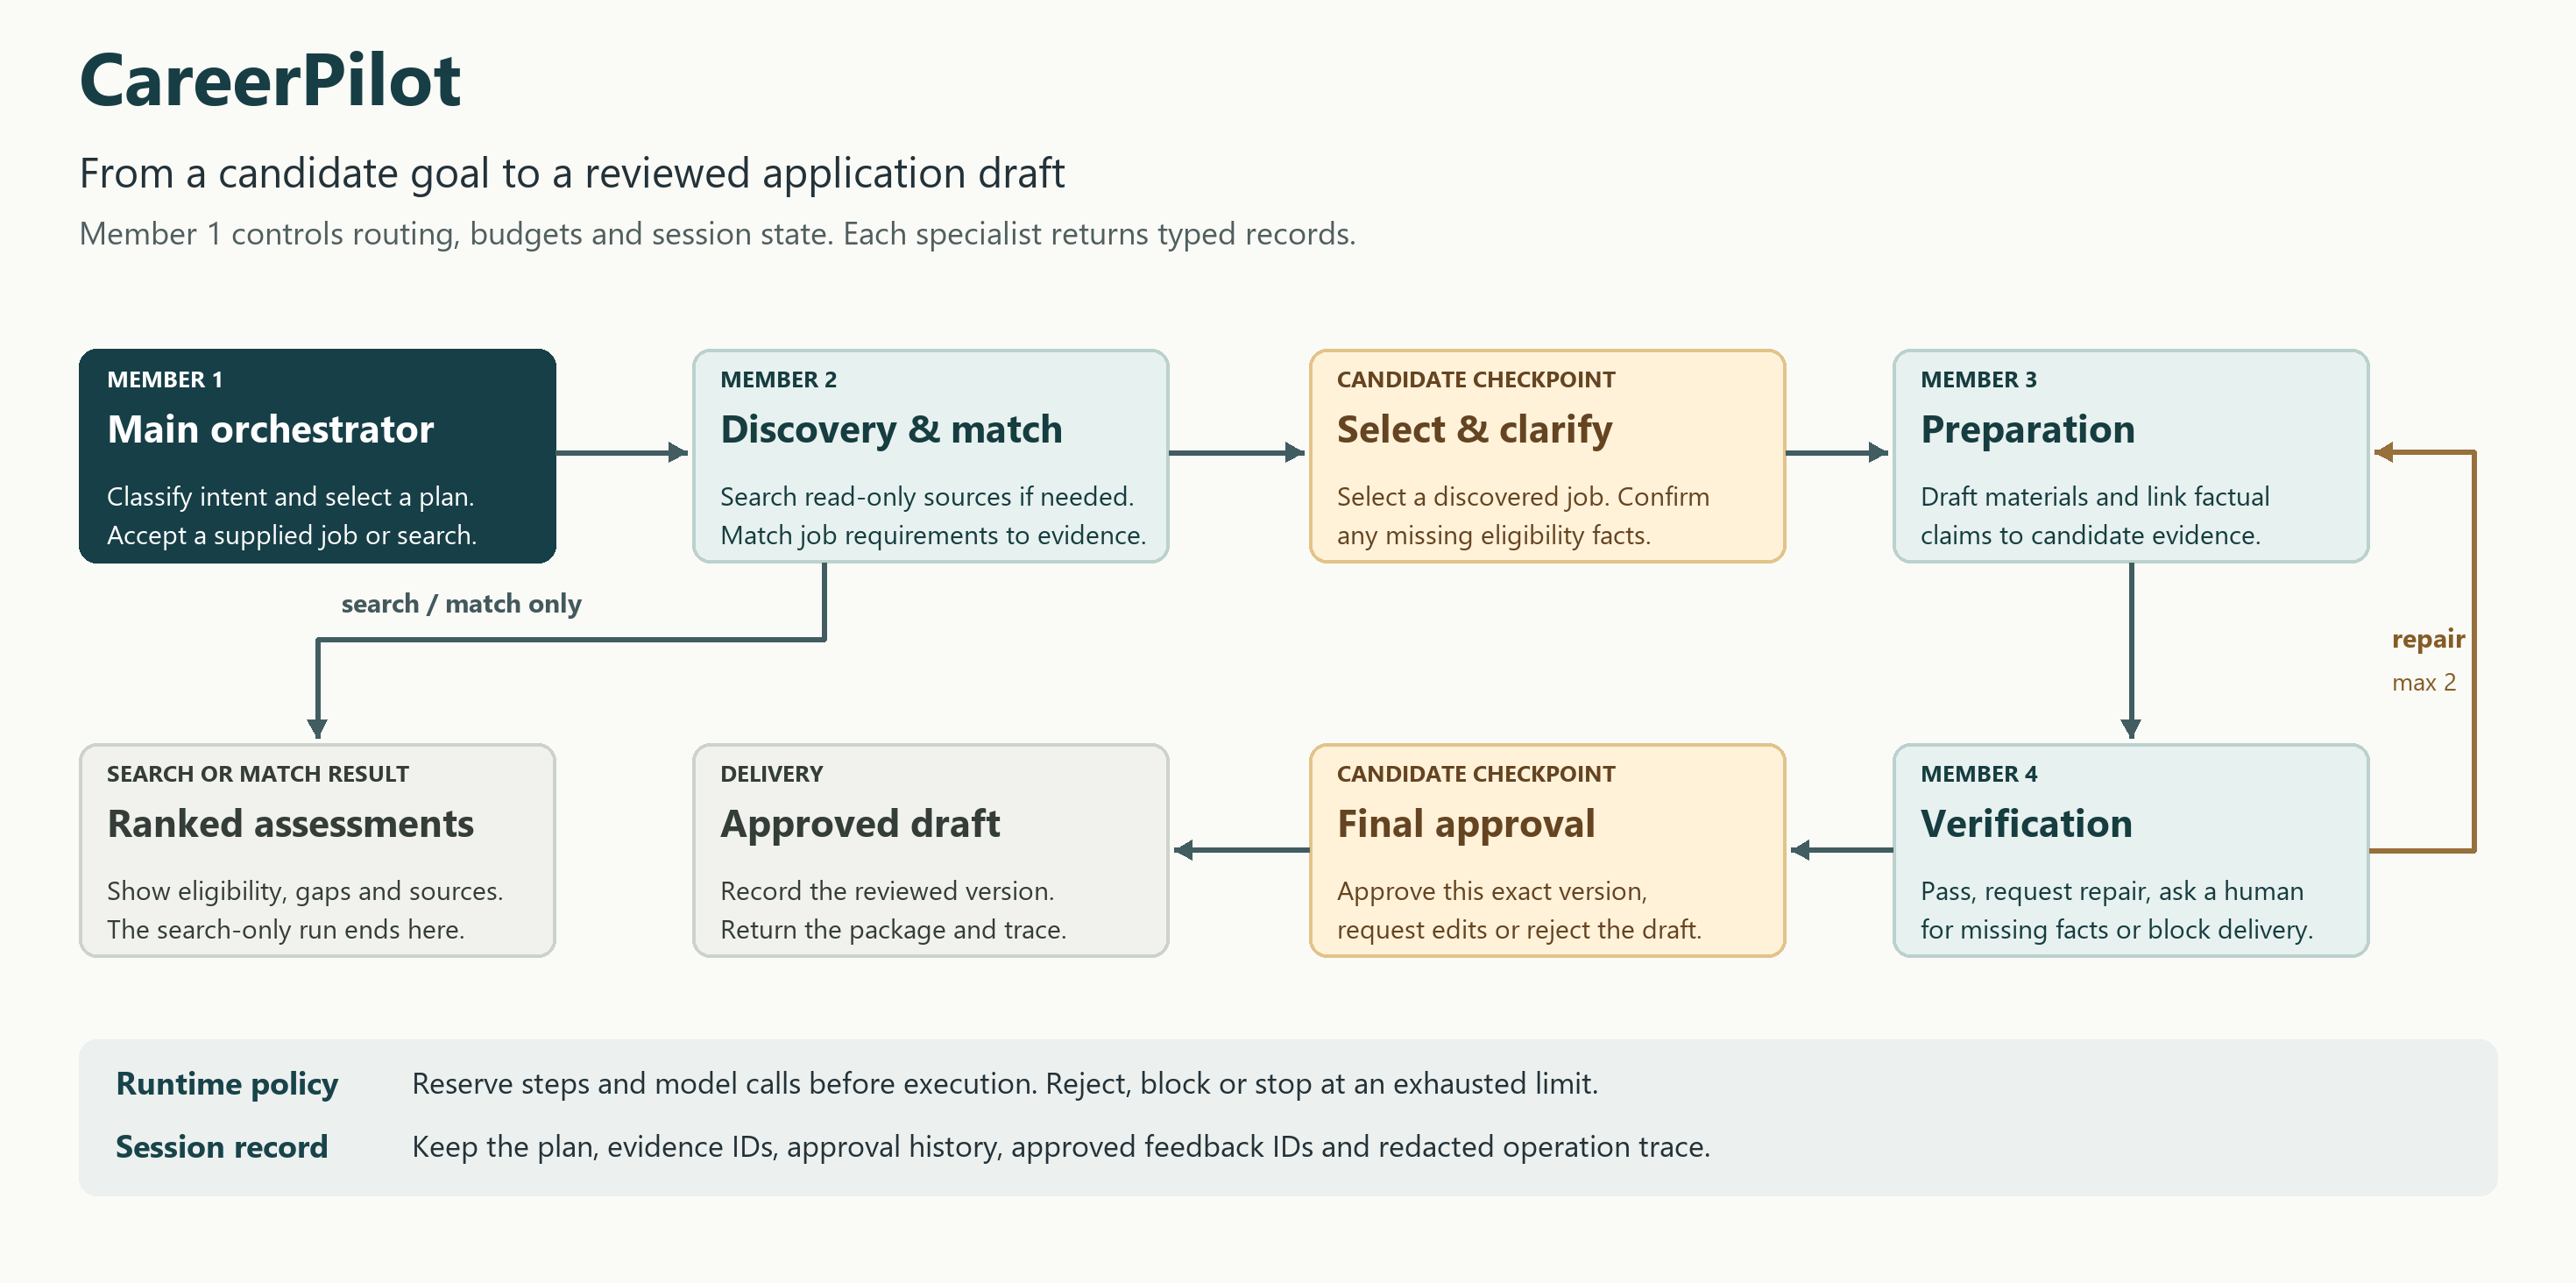

## Set up the offline session
Open this notebook from the project root with the project Python environment. In Colab, upload or clone the project directory and change the working directory to the folder containing `careerpilot/`. Install the base packages with `%pip install -r requirements.txt` if needed.

In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
from careerpilot.orchestrator import Orchestrator
from careerpilot.replay import (
    ReplayDiscovery, ReplayPreparation, ReplayVerification, load_evidence, load_jobs,
)
from careerpilot.session import load_session, save_session

INTERACTIVE = False
flow = Orchestrator(ReplayDiscovery(), ReplayPreparation(), ReplayVerification())
jobs = {job.job_id: job for job in load_jobs()}

## 1 · Search across a catalogue
The candidate wants up to three roles in Singapore, prefers Python and machine learning, and rules out jobs requiring more than two years of experience. Review the eligibility labels before selecting a job.

In [2]:
request = (
    "Find three roles in Singapore. "
    "Prioritize Python and machine learning. "
    "Exclude roles requiring more than two years of experience."
)
search = flow.start(request, load_evidence())
assert search.status == "completed" and search.package is None
print("Intent:", search.goal.intent)
print("Plan:", " → ".join(step.action for step in search.plan))
for match in search.matches:
    print(f"{match.eligibility:10}  {jobs[match.job_id].title}")
    print(" " * 12 + " ".join(match.gaps or match.reasons))
print("Confirmed eligible:", sum(m.eligibility == "eligible" for m in search.matches))

Intent: search
Plan: classify → discover → match → deliver_shortlist
unknown     Data Science Research Intern
            Are you authorised to work in Singapore?
unknown     AI Engineering Intern
            Are you authorised to work in Singapore?
ineligible  Senior Machine Learning Engineer
            The role requires 3 years, exceeding the requested maximum of 2.
Confirmed eligible: 0


## 2 · Prepare a draft for one supplied job
The candidate has selected the AI Engineering Intern role. The orchestrator can skip discovery. It must still match the evidence and resolve the job's work-authorisation requirement before drafting.

In [3]:
chosen = next(job for job in jobs.values() if job.title == "AI Engineering Intern")
session = flow.start("Prepare an application for this job.", load_evidence(), jobs=[chosen])
assert session.status == "awaiting_clarification" and session.package is None
print("Intent:", session.goal.intent)
print("Calls made:", " → ".join(event.tool for event in session.trace))
print("State:", session.status)
print("Question:", session.pending_questions[0])

Intent: prepare
Calls made: classify → match
State: awaiting_clarification
Question: Are you authorised to work in Singapore?


### Resume from the checkpoint
This round-trip uses a temporary local file. The answer belongs to the fictional candidate. An affirmative answer allows the match to be checked again. A negative answer stops the package, and an unknown answer leaves it paused.

In [4]:
with TemporaryDirectory() as directory:
    saved = save_session(session, Path(directory) / "session.json")
    session = load_session(saved)

answer = input("Synthetic work authorisation [yes/no/unknown]: ").strip().lower() if INTERACTIVE else "yes"
if answer not in {"yes", "no", "unknown"}:
    raise ValueError("Choose yes, no or unknown.")
print("Manual answer:" if INTERACTIVE else "Scripted fixture answer:", answer)
if answer != "unknown":
    question = next(req for req in chosen.requirements if req.ats_question)
    original = next(item for item in session.evidence if item.fact_key == question.fact_key)
    clarification = original.model_copy(update={
        "text": f"Synthetic candidate's answer to the eligibility question: {answer}.",
        "provenance": "Candidate response at the demonstration checkpoint.",
        "confirmed": True,
        "boolean_value": answer == "yes",
    })
    flow.clarify(session, [clarification])
print("State:", session.status)
if session.package:
    print(f"Review: {session.review.decision}  |  Draft version: {session.package.version}")
    print(session.package.resume_draft)
    print(session.package.cover_letter)
    for question, response in session.package.ats_answers.items():
        print(question, "→", response if response is not None else "(unanswered)")

Scripted fixture answer: yes
State: awaiting_approval
Review: pass  |  Draft version: 1
# Resume draft for AI Engineering Intern

- Completed a machine learning course project comparing supervised classification models. [CP-EV-002]
- Completed Python programming coursework covering data structures and basic scripting. [CP-EV-001]
- Used SQL in a database fundamentals course. [CP-EV-003]
# Cover letter draft for AI Engineering Intern at Northstar Labs (synthetic)

Selected role: AI Engineering Intern at Northstar Labs (synthetic).
Source-backed candidate details follow.
- Completed a machine learning course project comparing supervised classification models. [CP-EV-002]
- Completed Python programming coursework covering data structures and basic scripting. [CP-EV-001]
- Used SQL in a database fundamentals course. [CP-EV-003]
Are you authorised to work in Singapore? → Yes


### Approve the reviewed version
Inspect a claim and its source before taking the final action. The checkpoint records the approved version. Candidate rejection ends the session. Both outcomes stay local.

In [5]:
if session.status == "awaiting_approval":
    draft = session.package
    claim, refs = next(iter(draft.claim_evidence.items()))
    print("Claim:", claim)
    print("Sources:", ", ".join(refs))
    choice = input(f"Draft {draft.version} [approve/reject]: ").strip().lower() if INTERACTIVE else "approve"
    if choice == "approve":
        flow.approve(session, draft.version)
    elif choice == "reject":
        flow.reject(session)
    else:
        raise ValueError("Choose approve or reject.")
    print("Manual decision:" if INTERACTIVE else "Scripted fixture decision:", choice)
print("State:", session.status, "| Approved version:", session.approved_version)

Claim: Completed a machine learning course project comparing supervised classification models.
Sources: CP-EV-002
Scripted fixture decision: approve
State: completed | Approved version: 1


## Check the trace
The trace records operation names, outcomes and usage. The two routes are easy to distinguish even without reading the draft. Paid-model performance and specialist quality require separate evaluation.

In [6]:
for label, state in [("Search only", search), ("Known job", session)]:
    print(f"{label}: {' → '.join(event.tool for event in state.trace)}")
    print(f"  {state.steps_used} bounded operations | {state.model_calls_used} model calls")
assert all(e.tool != "discover" for e in session.trace)
assert not any(e.tool == "prepare" for e in search.trace)
if not INTERACTIVE:
    assert session.status == "completed" and session.approved_version == session.package.version

Search only: classify → discover → match
  3 bounded operations | 0 model calls
Known job: classify → match → clarify → match → prepare → review → approve
  5 bounded operations | 0 model calls


**Handoff.** Implement the specialist protocols in `careerpilot/schemas.py` and replace their replay adapters in the setup cell. See `docs/integration.md` for inputs, return values and approval behavior.